# **Install**

In [ ]:
%pip install -q --upgrade jax-ai-stack optuna # Install JAX, Flax, Optax

# **Setup**

In [ ]:
# ============== SETUP ==============
import os, time, json, pickle
import jax, jax.numpy as jnp
import numpy as np
from flax import nnx
import optuna
import optax
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist

QUICK = True # For quick experemintation
TEST_RUN = True

BUDGETS = [2_560, 12_800, 32_000, 64_000, 128_000]                    # Training images seen per candidate during search
BATCH_SIZES = [32, 64, 128]
SEARCH_METHODS = ["GA", "MAP-Elites", "Optuna TPE", "Random search"]
SEEDS = [0, 1] if QUICK else [0, 1, 2, 3, 4]
CPG = 24                                                              # Candidate per generation (CPG)
GENERATIONS = 5 if QUICK else 20                                      # CPG * GENERATIONS - networks per search
EVAL_EVERY = 640                                                      # Evaluate every 640 images
THRESHOLD = [0.75, 0.80, 0.85]                                        # speed - accuracy models need to reach

TOP_K, RECHECK_SEEDS = 5, 3
EPOCHS = 2 if QUICK else 20
N_TRAIN = 50_000
SPLIT_SEED = 42
DATA_SEED = 1234
SGD_MOMENTUM = 0.9

# Search space - genes and their ranges
SEARCH_SPACE = {
    "lr": ("log", 1e-4, 1.0),
    "optimizer": ("choice", ["sgd", "adam"]),
    "batch_size": ("choice", BATCH_SIZES),
    "layers": ("choice", [1, 2, 3]),                                # number of hidden Dense layers
    "width": ("int", 16, 256),                                      # units per hidden layer
    "activation": ("choice", ["relu", "tanh"]),
}

if TEST_RUN:
    BUDGETS, SEEDS, GENERATIONS, TOP_K, RECHECK_SEEDS = [2_560], [0], 2, 3, 1

# Baseline models
BASELINES = {
    "Adam 1e-3": dict(lr=1e-3, optimizer="adam", batch_size=128, layers=2, width=128, activation="relu"),
    "Adam 3e-4": dict(lr=3e-4, optimizer="adam", batch_size=128, layers=2, width=128, activation="relu"),
    "SGD 1e-2":  dict(lr=1e-2, optimizer="sgd",  batch_size=128, layers=2, width=128, activation="relu"),
}
N_GENES = len(SEARCH_SPACE)

def decode(genome):
    """Genome -> decode -> Hyperparameters"""
    g = np.clip(np.asarray(genome, dtype=float), 0.0, 1.0)
    hp = {}
    for x, (name, spec) in zip(g, SEARCH_SPACE.items()):
        kind = spec[0]
        if kind == "log":
            lo, hi = np.log10(spec[1]), np.log10(spec[2])
            hp[name] = float(10 ** (lo + x * (hi - lo)))
        elif kind == "int":
            hp[name] = int(round(spec[1] + x * (spec[2] - spec[1])))
        else:
            options = spec[1]
            hp[name] = options[min(int(x * len(options)), len(options) - 1)]
    return hp

def encode(hp):
    """Hyperparameters -> encode -> Genome"""
    g = []
    for name, spec in SEARCH_SPACE.items():
        kind, v = spec[0], hp[name]
        if kind == "log":
            lo, hi = np.log10(spec[1]), np.log10(spec[2])
            g.append((np.log10(v) - lo) / (hi - lo))
        elif kind == "int":
            g.append((v - spec[1]) / (spec[2] - spec[1]))
        else:
            options = spec[1]
            g.append((options.index(v) + 0.5) / len(options))
    return np.array(g)

def describe(hp):
    return (f"{hp['optimizer']:<4} lr={hp['lr']:.4f} batch={hp['batch_size']:3d} "
            f"{hp['layers']}x{hp['width']:3d} {hp['activation']}")

def n_params(hp, n_in=784, n_out=10):
    w, L = hp["width"], hp["layers"]
    return n_in * w + w + (L - 1) * (w * w + w) + w * n_out + n_out



# MAP-Elites (Learning rate * Number of network parameters)
GRID_BINS = 8
GOOD_CELL_MARGIN = 0.03
_P_MIN = n_params(dict(width=16, layers=1))
_P_MAX = n_params(dict(width=256, layers=3))

def grid_cell(hp):
    """Return the (row, col) cell of the diversity grid for one network."""
    lr_pos = (np.log10(hp["lr"]) + 4) / 4                                    # 0..1
    size_pos = (np.log10(n_params(hp)) - np.log10(_P_MIN)) / (np.log10(_P_MAX) - np.log10(_P_MIN))
    to_bin = lambda p: int(np.clip(p * GRID_BINS, 0, GRID_BINS - 1))
    return to_bin(lr_pos), to_bin(size_pos)

def sample_order(n_samples, seed=DATA_SEED):
    """Order of training images: identical for every network. Reshuffles each epoch,
    so budgets larger than 50,000 images work."""
    rng = np.random.default_rng(seed)
    n_epochs = -(-n_samples // N_TRAIN)
    return np.concatenate([rng.permutation(N_TRAIN) for _ in range(n_epochs)])[:n_samples]

print("JAX backend:", jax.default_backend(), "| devices:", jax.devices())


/usr/local/lib/python3.13/dist-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda13_plugin version 0.11.1 is installed, but it is not compatible with the installed jaxlib version 0.8.0, so it will not be used.
  warnings.warn(
ERROR:2026-10-25 11:49:56,757:jax._src.xla_bridge:473: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 471, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda13/__init__.py", line 378, in initialize
    xla_client.register_custom_type_handler(
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: module 'jaxlib.xla_client' has no attribute 'register_custom_type_handler'. Did you mean: 'register_custom_type_id_handler'?
ERROR:jax._src.xla_bridge:Jax plugin configuration error: Ex

JAX backend: gpu | devices: [CudaDevice(id=0)]


# **Load Data**

In [ ]:
#Loading data
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize images to [0, 1]
x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

# Create a fixed 50k/10k training-validation split
rng = np.random.default_rng(42)
indices = rng.permutation(len(x_train))

train_idx = indices[:50000]
val_idx = indices[50000:]

x_val, y_val = x_train[val_idx], y_train[val_idx]
x_train, y_train = x_train[train_idx], y_train[train_idx]

# Flatten 28x28 images
x_train = jnp.asarray(x_train.reshape(-1, 784))
x_val = jnp.asarray(x_val.reshape(-1, 784))
x_test = jnp.asarray(x_test.reshape(-1, 784))

y_train = jnp.asarray(y_train)
y_val = jnp.asarray(y_val)
y_test = jnp.asarray(y_test)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training: (50000, 784)
Validation: (10000, 784)
Test: (10000, 784)


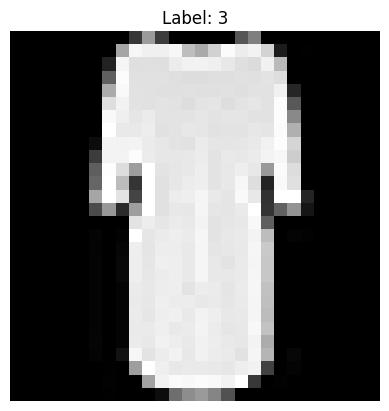

In [ ]:
#Show image
plt.imshow(x_train[0].reshape(28, 28), cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

# **Training**

In [ ]:
# ============== TRAINING (parallelism - sppeds up learning a lot) ==============
MAX_WIDTH = SEARCH_SPACE["width"][2]
GROUP = 8

def init_params(key, width):
    """Weights for one max-size network"""
    k = jax.random.split(key, 4)
    dense = lambda kk, n_in, n_out, fan_in: jax.random.normal(kk, (n_in, n_out)) / jnp.sqrt(fan_in)
    return dict(W1=dense(k[0], 784, MAX_WIDTH, 784),         b1=jnp.zeros(MAX_WIDTH),
                W2=dense(k[1], MAX_WIDTH, MAX_WIDTH, width), b2=jnp.zeros(MAX_WIDTH),
                W3=dense(k[2], MAX_WIDTH, MAX_WIDTH, width), b3=jnp.zeros(MAX_WIDTH),
                Wo=dense(k[3], MAX_WIDTH, 10, width),        bo=jnp.zeros(10))

def forward(p, cfg, x):
    """MLP with cfg['layers'] hidden layers of cfg['width'] units (the rest is masked out)."""
    mask = (jnp.arange(MAX_WIDTH) < cfg["width"]).astype(jnp.float32)
    act = lambda z: jnp.where(cfg["tanh"], jnp.tanh(z), jax.nn.relu(z))
    h = act(x @ p["W1"] + p["b1"]) * mask
    h = jnp.where(cfg["layers"] >= 2, act(h @ p["W2"] + p["b2"]) * mask, h)   # unused layer = skip
    h = jnp.where(cfg["layers"] >= 3, act(h @ p["W3"] + p["b3"]) * mask, h)
    return h @ p["Wo"] + p["bo"]

def accuracy(p, cfg, x, y):
    return jnp.mean(jnp.argmax(forward(p, cfg, x), axis=1) == y)

def train_net(cfg, key, batches, x_tr, y_tr, x_v, y_v, x_te, y_te):
    """Train ONE network"""
    params = init_params(key, cfg["width"])
    adam, sgd = optax.adam(cfg["lr"]), optax.sgd(cfg["lr"], momentum=SGD_MOMENTUM)
    opt_state = (adam.init(params), sgd.init(params))

    def loss(p, xb, yb):
        return optax.softmax_cross_entropy_with_integer_labels(forward(p, cfg, xb), yb).mean()

    def step(carry, idx):
        p, (s_adam, s_sgd) = carry
        g = jax.grad(loss)(p, x_tr[idx], y_tr[idx])
        u_adam, s_adam = adam.update(g, s_adam, p)
        u_sgd, s_sgd = sgd.update(g, s_sgd, p)
        u = jax.tree_util.tree_map(lambda a, b: jnp.where(cfg["adam"], a, b), u_adam, u_sgd)
        return (optax.apply_updates(p, u), (s_adam, s_sgd)), None

    def train_and_eval(carry, idx_chunk):
        carry, _ = jax.lax.scan(step, carry, idx_chunk)
        return carry, accuracy(carry[0], cfg, x_v, y_v)

    (params, _), curve = jax.lax.scan(train_and_eval, (params, opt_state), batches)
    return curve, accuracy(params, cfg, x_te, y_te)

# vmap = train many networks at once; jit = compile. in_axes: 0 = differs per network, None = shared
train_many = jax.jit(jax.vmap(train_net, in_axes=(0, 0, None, None, None, None, None, None, None)))

def train_population(hps, budget, seed, eval_every=None):
    """Train a list of networks in parallel"""
    every = eval_every or budget
    budget = (budget // every) * every
    order = sample_order(budget)
    keys = jax.random.split(jax.random.PRNGKey(seed), len(hps))
    val, test, curves = np.zeros(len(hps)), np.zeros(len(hps)), [None] * len(hps)

    for bs in sorted({hp["batch_size"] for hp in hps}):
        batches = jnp.asarray(order.reshape(budget // every, every // bs, bs))
        ids = [i for i, hp in enumerate(hps) if hp["batch_size"] == bs]
        for s in range(0, len(ids), CPG):
            part = ids[s:s + CPG]
            size = min(CPG, -(-len(part) // GROUP) * GROUP)
            padded = part + [part[-1]] * (size - len(part))
            cfg = dict(lr=jnp.array([hps[i]["lr"] for i in padded], dtype=jnp.float32),
                       adam=jnp.array([hps[i]["optimizer"] == "adam" for i in padded]),
                       layers=jnp.array([hps[i]["layers"] for i in padded]),
                       width=jnp.array([hps[i]["width"] for i in padded]),
                       tanh=jnp.array([hps[i]["activation"] == "tanh" for i in padded]))
            cu, te = train_many(cfg, keys[jnp.array(padded)], batches,
                                x_train, y_train, x_val, y_val, x_test, y_test)
            cu, te = np.asarray(cu), np.asarray(te)
            for j, i in enumerate(part):
                curves[i], val[i], test[i] = [float(a) for a in cu[j]], cu[j, -1], te[j]
    return val, curves, test

def train_one(hp, budget, seed, eval_every=None):
    """Train one network. Returns (final val accuracy, learning curve)."""
    val, curves, _ = train_population([hp], budget, seed, eval_every)
    return float(val[0]), (curves[0] if eval_every else [])

def fitness(hps, budget, seed):
    """FITNESS = validation accuracy after `budget` training images, for each network."""
    return train_population(hps, budget, seed)[0]


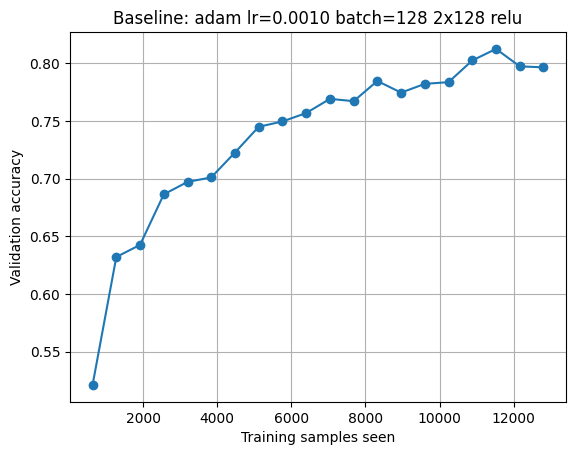

Final validation accuracy: 79.64%


In [ ]:
# Qucik model check
hp = BASELINES["Adam 1e-3"]
acc, curve = train_one(hp, budget=12_800, seed=0, eval_every=EVAL_EVERY)
samples = np.arange(1, len(curve) + 1) * EVAL_EVERY
plt.plot(samples, curve, marker="o"); plt.grid(True)
plt.xlabel("Training samples seen"); plt.ylabel("Validation accuracy")
plt.title(f"Baseline: {describe(hp)}"); plt.show()
print(f"Final validation accuracy: {acc:.2%}")

# **Search implementation**

In [ ]:
def mutate(genomes, rng, sigma=0.1):
    """add small random noise to every gene"""
    return np.clip(genomes + sigma * rng.normal(size=genomes.shape), 0.0, 1.0)

def crossover(a, b, rng):
    """Uniform crossover: every gene comes from parent a or parent b with 50% chance."""
    return np.where(rng.random(a.shape) < 0.5, a, b)

class RandomSearch:
    """Baseline search: random genomes."""
    def __init__(self, seed):
        self.rng = np.random.default_rng(seed)

    def propose(self, n):
        return self.rng.random((n, N_GENES))

    def update(self, genomes, fit):
        pass

class GA:
    """Genetic algorithm: parent selection based on accuracy, crossover and mutation"""
    def __init__(self, seed):
      self.rng = np.random.default_rng(seed)
      self.pop = None # Population
      self.fit = None # Fitness

    def propose(self, n):
      # First generation is random
      if self.pop is None:
        return self.rng.random((n, N_GENES))

      # Accuracy based selection
      w = self.fit - self.fit.min() + 1e-6
      p = w / w.sum()
      parents_a = self.pop[self.rng.choice(len(self.pop), n, p=p)]
      parents_b = self.pop[self.rng.choice(len(self.pop), n, p=p)]
      return mutate(crossover(parents_a, parents_b, self.rng), self.rng)

    def update(self, genomes, fit):
      if self.pop is None:
        self.pop, self.fit = np.array(genomes), np.array(fit)
        return

      # Competition between parent and children
      all_g = np.concatenate([self.pop, genomes])
      all_f = np.concatenate([self.fit, fit])

      # Keep the best candidates
      keep = np.argsort(all_f)[::-1][:len(genomes)]
      self.pop, self.fit = all_g[keep], all_f[keep]

class MAPElites:
    """Keeps the best network in every cell of the grid. New candidates are mutated children of random best networks."""
    def __init__(self, seed):
      self.rng = np.random.default_rng(seed)
      self.archive = {}

    def propose(self, n):
      # First generation is random
      if not self.archive:
            return self.rng.random((n, N_GENES))

      elites = np.array([g for g, f in self.archive.values()])
      parents_a = elites[self.rng.integers(len(elites), size=n)]
      parents_b = elites[self.rng.integers(len(elites), size=n)]
      return mutate(crossover(parents_a, parents_b, self.rng), self.rng)

    def update(self, genomes, fit):
      for g, f in zip(genomes, fit):
        cell = grid_cell(decode(g))
        if cell not in self.archive or f > self.archive[cell][1]:
          self.archive[cell] = (g, f)

class OptunaTPE:
    """A model based optimizer. Suggests genomes that its model thinks will score well."""
    def __init__(self, seed):
      self.study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
      self.trials = []

    def propose(self, n):
      self.trials = [self.study.ask() for _ in range(n)]
      return np.array([[t.suggest_float(f"g{i}", 0.0, 1.0) for i in range(N_GENES)]for t in self.trials])

    def update(self, genomes, fit):
      for t, f in zip(self.trials, fit):
            self.study.tell(t, float(np.nan_to_num(f)))

SEARCH_CLASSES = {"GA": GA, "MAP-Elites": MAPElites, "Optuna TPE": OptunaTPE, "Random search": RandomSearch}

# **Experimental run**

In [ ]:
def run_search(method, budget, seed):
    """Shared loop for all four search methods."""
    all_genomes, all_fitness = [], []
    for gen in range(GENERATIONS):
        # picks 24 candidates
        genomes = method.propose(CPG)
        hps = [decode(g) for g in genomes]

        # train + measure
        fit = fitness(hps, budget, seed)

         # learn from results
        method.update(genomes, fit)
        all_genomes += list(genomes); all_fitness += list(fit)
    return np.array(all_genomes), np.array(all_fitness)

runs = []
t0 = time.time()
for budget in BUDGETS:
    for name, Method in SEARCH_CLASSES.items():
        for seed in SEEDS:
            t = time.time()
            G, F = run_search(Method(seed), budget, seed)

            # re-check the TOP_K best with new seeds; the best average is the winner
            top = G[np.argsort(F)[::-1][:TOP_K]]
            top_hps = [decode(g) for g in top]
            recheck = np.mean([fitness(top_hps, budget, seed=1000 + 10 * seed + r)
                               for r in range(RECHECK_SEEDS)], axis=0)
            winner = top[np.argmax(recheck)]

            runs.append(dict(budget=budget, method=name, seed=seed, genomes=G, fitness=F,
                             winner=winner, winner_recheck=float(recheck.max())))
            print(f"budget={budget:>7} {name:<14} seed {seed}: best {F.max():.4f} "
                  f"rechecked {recheck.max():.4f} [{time.time() - t:.0f}s]  {describe(decode(winner))}")
print(f"All searches done in {time.time() - t0:.0f}s")

budget=   2560 GA             seed 0: best 0.7759 rechecked 0.7651 [18s]  adam lr=0.0058 batch= 64 2x165 tanh


[I 2026-10-25 12:00:18,166] A new study created in memory with name: no-name-472bad91-989f-4349-a38f-f5910ba8fce2


budget=   2560 MAP-Elites     seed 0: best 0.7640 rechecked 0.7669 [8s]  adam lr=0.0058 batch= 64 2x165 tanh
budget=   2560 Optuna TPE     seed 0: best 0.7760 rechecked 0.7826 [1s]  adam lr=0.0048 batch= 64 1x181 tanh
budget=   2560 Random search  seed 0: best 0.7640 rechecked 0.7731 [1s]  adam lr=0.0038 batch= 64 2x 63 tanh
All searches done in 28s


# **Evolution**

In [ ]:
# TODO

# **Analysis**

In [ ]:
# TODO